# Group comparison — six models on the same cleaned feature set


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import balanced_accuracy_score, recall_score
from sklearn.neighbors import NearestNeighbors

OUT = "../results/outputs/"
TARGET, HYPO = "next_risk_class", "Hypoglycemic"
MODELS = [("Logistic Regression", "logistic_regression", "logistic"),
          ("Decision Tree",       "decision_tree",       "decision"),
          ("Random Forest",       "random_forest",       "random"),
          ("SVM (RBF)",           "svm",                 "svm"),
          ("Gradient Boosting",   "gradient_boosting",   "gradient"),
          ("KNN",                 "knn",                 "knn")]
res = {name: pd.read_csv(f"{OUT}model_results_{key}.csv").iloc[0] for name, key, _ in MODELS}
print("Loaded results for:", ", ".join(res))

Loaded results for: Logistic Regression, Decision Tree, Random Forest, SVM (RBF), Gradient Boosting, KNN


## 1. Are the six models really comparable?
Each notebook saves the exact list of input features it used. If the lists differ, the models were trained on different
information and the comparison below would not be valid.

In [2]:
lists = {n: r["feature_list"] for n, r in res.items()}
same = len(set(lists.values())) == 1
print("Number of input features per model:", {n: int(r["n_features"]) for n, r in res.items()})
print("All six models use the identical feature list:", same)
print("'reading_index' in any feature list         :", any("reading_index" in v for v in lists.values()))
print("'daily_total_insulin' in any feature list   :", any("daily_total_insulin" in v for v in lists.values()))
if not same:
    raise ValueError("The saved feature lists differ - re-run the model notebooks so that all six use the same features.")
print("\nThe 21 features:", ", ".join(next(iter(lists.values())).split(";")))

Number of input features per model: {'Logistic Regression': 21, 'Decision Tree': 21, 'Random Forest': 21, 'SVM (RBF)': 21, 'Gradient Boosting': 21, 'KNN': 21}
All six models use the identical feature list: True
'reading_index' in any feature list         : False
'daily_total_insulin' in any feature list   : False

The 21 features: hour, is_weekend, glucose_mg_dl, prev_glucose, hours_since_prev, rolling_mean_3, rolling_std_3, insulin_regular_6h, insulin_nph_6h, insulin_ultralente_6h, meals_6h, exercise_6h, hypo_symptoms_6h, dow_sin, dow_cos, ctx_post_meal, ctx_pre_breakfast, ctx_pre_lunch, ctx_pre_snack, ctx_pre_supper, ctx_unspecified


## 2. Test-set results (default decision rule)
Each model's chosen configuration, refit on the full training set and scored once on the test set. The default decision
rule is "predict the class with the highest probability or score", which is not tuned for catching hypoglycemia; the
threshold analysis in Section 7 looks at that separately.

In [3]:
main_cols = {"balanced_acc": "balanced accuracy", "hypo_recall": "hypo recall", "hypo_precision": "hypo precision",
             "hypo_f2": "hypo F2", "accuracy": "accuracy", "macro_f1": "macro F1",
             "test_hypo_auc": "ROC AUC (hypo)", "test_macro_auc": "ROC AUC (macro)", "test_flagged_share": "readings flagged"}
raw = pd.DataFrame({n: {c: r.get(c, np.nan) for c in list(main_cols) + ["cv_balanced_acc", "cv_balanced_acc_std",
        "train_cv_gap_balanced_acc", "time_ordered_balanced_acc", "time_ordered_hypo_recall", "group_cv_balanced_acc",
        "group_cv_hypo_recall"]} for n, r in res.items()}).T.astype(float)
table = raw[list(main_cols)].rename(columns=main_cols)
print(table.round(3).to_string())
print("\nHighest observed value on each measure (a high value on 'readings flagged' is not better or worse):")
for lab in main_cols.values():
    if lab != "readings flagged":
        print(f"  {lab:18s} {table[lab].idxmax():20s} {table[lab].max():.3f}")

                     balanced accuracy  hypo recall  hypo precision  hypo F2  accuracy  macro F1  ROC AUC (hypo)  ROC AUC (macro)  readings flagged
Logistic Regression              0.478        0.519           0.182    0.379     0.461     0.433           0.646            0.652             0.330
Decision Tree                    0.485        0.565           0.180    0.396     0.449     0.428           0.655            0.656             0.364
Random Forest                    0.503        0.416           0.234    0.360     0.521     0.475           0.716            0.701             0.205
SVM (RBF)                        0.507        0.523           0.216    0.407     0.495     0.462           0.676            0.672             0.281
Gradient Boosting                0.504        0.455           0.217    0.373     0.513     0.471           0.709            0.701             0.243
KNN                              0.529        0.555           0.224    0.429     0.519     0.484           0.733

## 3. Validation evidence — how far can the test scores be trusted?
The split is row-wise (all 70 patients are in both train and test), so a test score can be flattered by a patient's
neighbouring readings. Two checks on the training set address that:
- **Time-ordered:** train on each patient's earlier 80% of readings, validate on their later 20% — the realistic setting
  for *already-monitored* patients, who are the intended use case.
- **GroupKFold:** validation patients are never seen in training — how well the model generalises to *new* patients.

The cross-validation standard deviation shows how much a score moves from fold to fold.

In [4]:
val_cols = {"cv_balanced_acc": "CV balanced acc", "cv_balanced_acc_std": "CV std", "time_ordered_balanced_acc": "time-ordered balanced acc",
            "time_ordered_hypo_recall": "time-ordered hypo recall", "group_cv_balanced_acc": "GroupKFold balanced acc",
            "group_cv_hypo_recall": "GroupKFold hypo recall", "train_cv_gap_balanced_acc": "train - CV gap"}
val = raw[list(val_cols)].rename(columns=val_cols)
val["test balanced acc"] = raw["balanced_acc"]
val["unseen patients - CV"] = raw["group_cv_balanced_acc"] - raw["cv_balanced_acc"]
print(val.round(3).to_string())
print("\nNote: the train - CV gap of KNN is inflated by construction (each training row is its own nearest neighbour).")

                     CV balanced acc  CV std  time-ordered balanced acc  time-ordered hypo recall  GroupKFold balanced acc  GroupKFold hypo recall  train - CV gap  test balanced acc  unseen patients - CV
Logistic Regression            0.480   0.011                      0.499                     0.532                    0.460                   0.498           0.002              0.478                -0.020
Decision Tree                  0.480   0.013                      0.514                     0.566                    0.454                   0.535           0.058              0.485                -0.026
Random Forest                  0.516   0.013                      0.553                     0.519                    0.486                   0.419           0.158              0.503                -0.030
SVM (RBF)                      0.506   0.006                      0.547                     0.591                    0.472                   0.483           0.067              0.507   

### How much of the time-ordered score is just *which patient it is*?
A reference point that uses **no features at all**: for each patient, predict the class that is most over-represented in
that patient's *earlier* readings relative to everyone else, and score it on their later readings. A model has to beat this
to show that its features add anything beyond knowing the patient. (For already-monitored patients, patient-specific
information is legitimately available; the baseline is a yardstick, not a model to deploy.)

In [5]:
train = pd.read_csv(OUT + "processed_dataset_train.csv")
ordered = train.assign(ts=pd.to_datetime(train["timestamp"])).sort_values(["patient_id", "ts", "reading_index"])
position = ordered.groupby("patient_id").cumcount()
n_rd = ordered.groupby("patient_id")["patient_id"].transform("size")
is_late = position >= np.floor(n_rd * 0.8)
early, late = ordered[~is_late], ordered[is_late]

global_prior = early[TARGET].value_counts(normalize=True)
patient_prior = early.groupby("patient_id")[TARGET].value_counts(normalize=True).unstack(fill_value=0)
ratio = patient_prior.reindex(late["patient_id"]).values / global_prior.reindex(patient_prior.columns).values
identity_pred = patient_prior.columns[ratio.argmax(axis=1)]
identity_ba = balanced_accuracy_score(late[TARGET], identity_pred)
identity_hr = recall_score(late[TARGET], identity_pred, labels=[HYPO], average="macro", zero_division=0)
print(f"'Patient identity alone' baseline, time-ordered: balanced accuracy {identity_ba:.3f}, hypo recall {identity_hr:.3f} "
      f"(a trivial model scores 0.333)")
print()
cmp_ = pd.DataFrame({"time-ordered balanced acc": raw["time_ordered_balanced_acc"],
                     "minus patient-identity baseline": raw["time_ordered_balanced_acc"] - identity_ba})
print(cmp_.round(3).to_string())

'Patient identity alone' baseline, time-ordered: balanced accuracy 0.507, hypo recall 0.532 (a trivial model scores 0.333)

                     time-ordered balanced acc  minus patient-identity baseline
Logistic Regression                      0.499                           -0.008
Decision Tree                            0.514                            0.007
Random Forest                            0.553                            0.045
SVM (RBF)                                0.547                            0.040
Gradient Boosting                        0.561                            0.053
KNN                                      0.589                            0.081


### A check on the highest-ranked model: does KNN find the same patient?
KNN predicts from the most similar stored readings. If those are often the same patient's other readings, KNN profits from
the row-wise structure of the data, and its lead should shrink for patients it has never seen. For an unseen patient the share
below is zero by construction. The check uses the unscaled features, as in KNN's chosen configuration.

In [6]:
test = pd.read_csv(OUT + "processed_dataset_test.csv")
features = next(iter(lists.values())).split(";")
chance = float((train["patient_id"].value_counts(normalize=True) ** 2).sum())
print(f"Chance that a random training reading belongs to the same patient as a given test reading: {chance:.1%}")
for k in (1, 10, 100):
    nn = NearestNeighbors(n_neighbors=k).fit(train[features])
    idx = nn.kneighbors(test[features], return_distance=False)
    same = (train["patient_id"].values[idx] == test["patient_id"].values[:, None]).mean()
    print(f"  {k:3d} nearest stored readings: {same:.1%} are from the same patient ({same / chance:.0f} times chance)")

Chance that a random training reading belongs to the same patient as a given test reading: 2.3%
    1 nearest stored readings: 36.6% are from the same patient (16 times chance)
   10 nearest stored readings: 29.4% are from the same patient (13 times chance)
  100 nearest stored readings: 18.9% are from the same patient (8 times chance)


## 4. Chosen settings
The optimum configuration each notebook selected (the one-standard-error band plus the analyst-chosen preference order).

In [7]:
setting_cols = ["feature_set", "scaling", "imbalance", "C", "gamma", "max_depth", "min_samples_leaf", "criterion",
                "max_features", "n_estimators", "learning_rate", "max_iter", "n_neighbors", "weights"]
settings = pd.DataFrame({n: {c: r[c] for c in setting_cols if c in r.index and pd.notna(r[c])} for n, r in res.items()}).T
print(settings.fillna("-").to_string())

                    feature_set         scaling      imbalance         C  max_depth min_samples_leaf criterion max_features n_estimators gamma learning_rate max_iter n_neighbors   weights
Logistic Regression         pca  StandardScaler  Class weights  0.000001          -                -         -            -            -     -             -        -           -         -
Decision Tree          original               -  Class weights         -          7               50      gini            -            -     -             -        -           -         -
Random Forest               all               -  Class weights         -  unlimited               30         -          0.5          100     -             -        -           -         -
SVM (RBF)              original               -  Class weights       1.0          -                -         -            -            -  0.05             -        -           -         -
Gradient Boosting      original               -  Class weigh

## 5. Figures

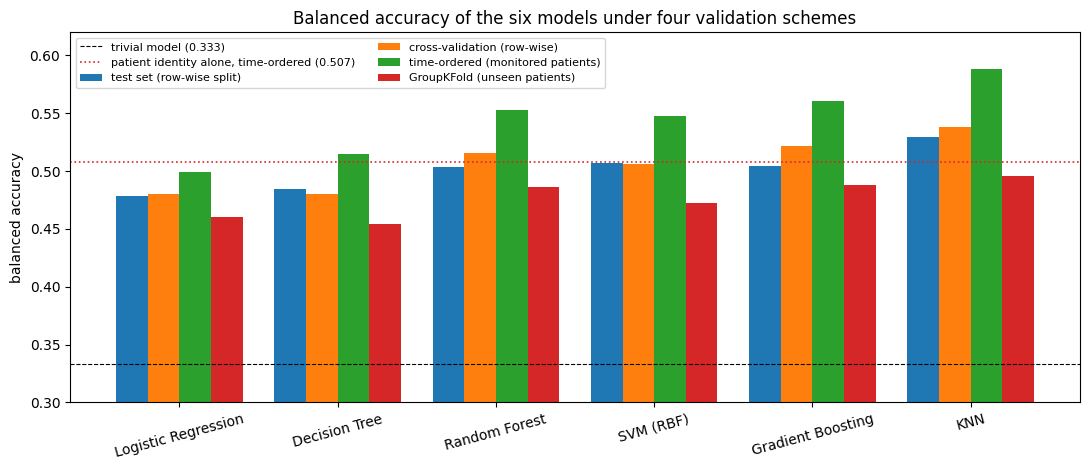

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.8))
schemes = [("balanced_acc", "test set (row-wise split)"), ("cv_balanced_acc", "cross-validation (row-wise)"),
           ("time_ordered_balanced_acc", "time-ordered (monitored patients)"), ("group_cv_balanced_acc", "GroupKFold (unseen patients)")]
x = np.arange(len(raw)); width = 0.2
for j, (c, lab) in enumerate(schemes):
    ax.bar(x + (j - 1.5) * width, raw[c], width, label=lab)
ax.axhline(1 / 3, color="black", ls="--", lw=0.8, label="trivial model (0.333)")
ax.axhline(identity_ba, color="tab:red", ls=":", lw=1.2, label=f"patient identity alone, time-ordered ({identity_ba:.3f})")
ax.set_xticks(x); ax.set_xticklabels(raw.index, rotation=15)
ax.set_ylim(0.3, 0.62); ax.set_ylabel("balanced accuracy"); ax.set_title("Balanced accuracy of the six models under four validation schemes")
ax.legend(fontsize=8, ncol=2, loc="upper left"); plt.tight_layout(); plt.show()

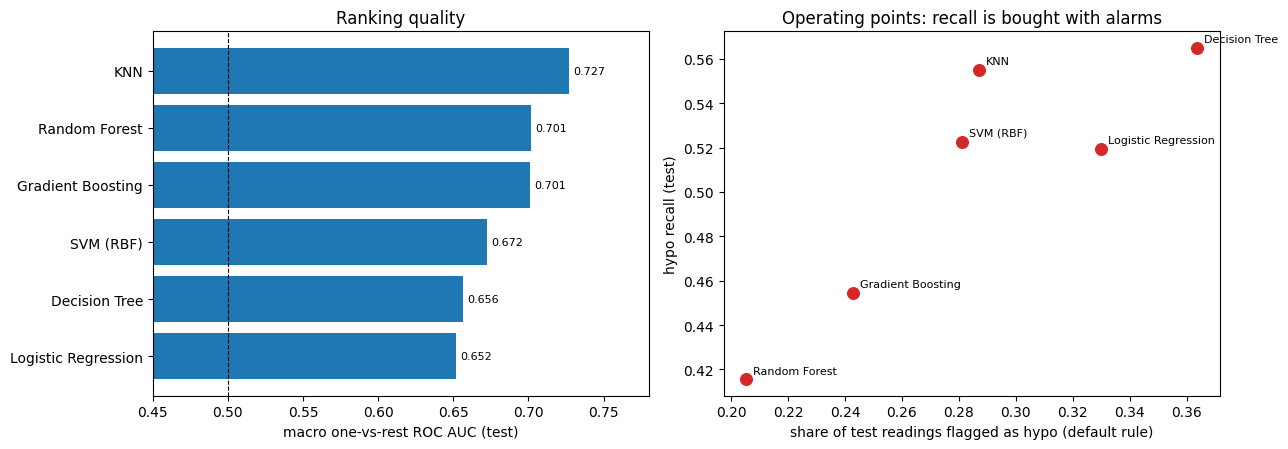

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
order = raw["test_macro_auc"].sort_values().index
axes[0].barh(order, raw.loc[order, "test_macro_auc"], color="tab:blue")
axes[0].axvline(0.5, color="black", ls="--", lw=0.8)
axes[0].set_xlim(0.45, 0.78); axes[0].set_xlabel("macro one-vs-rest ROC AUC (test)"); axes[0].set_title("Ranking quality")
for i, n in enumerate(order):
    axes[0].text(raw.loc[n, "test_macro_auc"] + 0.003, i, f"{raw.loc[n, 'test_macro_auc']:.3f}", va="center", fontsize=8)
axes[1].scatter(raw["test_flagged_share"], raw["hypo_recall"], s=70, color="tab:red")
for n in raw.index:
    axes[1].annotate(n, (raw.loc[n, "test_flagged_share"], raw.loc[n, "hypo_recall"]), textcoords="offset points",
                     xytext=(5, 4), fontsize=8)
axes[1].set_xlabel("share of test readings flagged as hypo (default rule)"); axes[1].set_ylabel("hypo recall (test)")
axes[1].set_title("Operating points: recall is bought with alarms")
plt.tight_layout(); plt.show()

## 6. Consistency of the ranking
A model that is genuinely stronger should rank high under *every* validation scheme, not just one. The table ranks the
six models on each measure (1 = highest observed value).

In [10]:
rank_cols = {"balanced_acc": "test balanced acc", "cv_balanced_acc": "CV balanced acc",
             "time_ordered_balanced_acc": "time-ordered balanced acc", "group_cv_balanced_acc": "GroupKFold balanced acc",
             "test_macro_auc": "test macro AUC"}
ranks = pd.DataFrame({lab: raw[c].rank(ascending=False) for c, lab in rank_cols.items()}).astype(int)
ranks["mean rank"] = ranks.mean(axis=1)
print(ranks.sort_values("mean rank").to_string())
gap = (raw["cv_balanced_acc"].max() - raw["cv_balanced_acc"]).round(3)
print("\nGap to the highest CV balanced accuracy, next to the model's own CV standard deviation:")
print(pd.DataFrame({"gap to highest": gap, "own CV std": raw["cv_balanced_acc_std"]}).sort_values("gap to highest").round(3).to_string())

                     test balanced acc  CV balanced acc  time-ordered balanced acc  GroupKFold balanced acc  test macro AUC  mean rank
KNN                                  1                1                          1                        1               1        1.0
Gradient Boosting                    3                2                          2                        2               3        2.4
Random Forest                        4                3                          3                        3               2        3.0
SVM (RBF)                            2                4                          4                        4               4        3.6
Decision Tree                        5                6                          5                        6               5        5.4
Logistic Regression                  6                5                          6                        5               6        5.6

Gap to the highest CV balanced accuracy, next to the m

## 7. Additional evaluation — alarm threshold for hypoglycemia detection
This section is **not used to choose or rank the models above**. The default decision rule is not tuned for catching
hypoglycemia, so each model notebook also picked an alarm threshold from **out-of-fold scores on the training set only**,
for three recall targets, and applied it to the test set once. Which recall level is acceptable is a clinical decision;
the table shows what each level costs in readings flagged and in false alarms.

In [11]:
frames = []
for name, key, tag in MODELS:
    try:
        frames.append(pd.read_csv(f"{OUT}threshold_analysis_{tag}.csv").assign(model=name))
    except FileNotFoundError:
        print(f"(threshold_analysis_{tag}.csv not found - run the {name} notebook to add it.)")
if frames:
    thr = pd.concat(frames, ignore_index=True)
    thr["false alarms per real hypo"] = (1 - thr["test hypo precision"]) / thr["test hypo precision"]
    thr["rule"] = thr["rule"].str.replace("threshold for out-of-fold recall ", "OOF recall target ", regex=False)
    thr["rule"] = thr["rule"].str.replace("default (highest score wins)", "default rule", regex=False)
    wides = {}
    for col, title in [("test hypo recall", "Test hypo recall"), ("test share flagged", "Share of test readings flagged"),
                       ("false alarms per real hypo", "False alarms per real hypo event")]:
        print(f"\n{title}")
        wide = thr.pivot(index="model", columns="rule", values=col).reindex([m[0] for m in MODELS])
        wides[col] = wide
        print(wide[[c for c in ["default rule", "OOF recall target 0.5", "OOF recall target 0.6", "OOF recall target 0.7"] if c in wide.columns]].round(3).to_string())
    print("\nTest recall minus the recall target (the thresholds were chosen on training data only, so this shows how well the target transferred)")
    dev = {f"target {t}": wides["test hypo recall"][f"OOF recall target {t}"] - t for t in [0.5, 0.6, 0.7]
           if f"OOF recall target {t}" in wides["test hypo recall"].columns}
    print(pd.DataFrame(dev).round(3).to_string())
else:
    print("No threshold files found.")


Test hypo recall
rule                 default rule  OOF recall target 0.5  OOF recall target 0.6  OOF recall target 0.7
model                                                                                                 
Logistic Regression         0.519                  0.536                  0.597                  0.688
Decision Tree               0.565                  0.552                  0.584                  0.718
Random Forest               0.416                  0.490                  0.604                  0.721
SVM (RBF)                   0.523                  0.513                  0.614                  0.705
Gradient Boosting           0.455                  0.468                  0.591                  0.718
KNN                         0.555                  0.471                  0.584                  0.701

Share of test readings flagged
rule                 default rule  OOF recall target 0.5  OOF recall target 0.6  OOF recall target 0.7
model                  

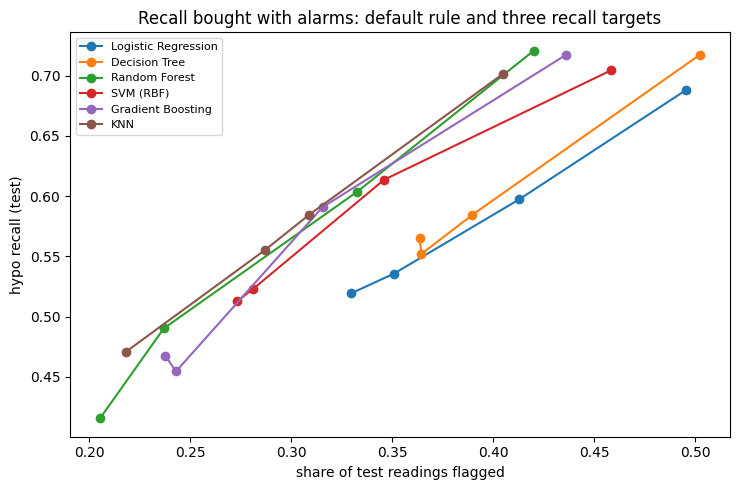

In [12]:
if frames:
    fig, ax = plt.subplots(figsize=(7.5, 5))
    for name, _, _ in MODELS:
        s = thr[thr.model == name].sort_values("test share flagged")
        if len(s): ax.plot(s["test share flagged"], s["test hypo recall"], marker="o", label=name)
    ax.set_xlabel("share of test readings flagged"); ax.set_ylabel("hypo recall (test)")
    ax.set_title("Recall bought with alarms: default rule and three recall targets")
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 8. Challenges, performance and expected behaviour
*(The points below are written from the tables above; each states what the evidence in this notebook supports and where it
stops.)*

**Performance.** Under every validation scheme the six models fall into the same rough groups: Logistic Regression and the
Decision Tree at the bottom, the Random Forest, SVM and Gradient Boosting in the middle, and KNN with the highest observed
values (Sections 2, 3 and 6). All of them remain modest in absolute terms: balanced accuracy only a little above the 0.333
of a trivial model, and ROC AUC well short of 1. The features carry real but limited information about the *next* reading.

**Patient identity matters.** A baseline that uses no features, only each patient's own earlier class frequencies, already
reaches a time-ordered balanced accuracy that the two weakest models do not clearly exceed (Section 3). For monitored
patients this is legitimate information, but it means part of every model's score reflects *who* the patient is, not only
the glucose, insulin and context features.

**The row-wise split flatters the test scores.** The test set shares its patients with the training set, and KNN in
particular predicts from the most similar stored readings; the check in Section 3 measures how often those belong to the same
patient. Its lead over the Random Forest and Gradient Boosting shrinks to about 0.01 on unseen patients (GroupKFold), against
about 0.03 on the test set and in time-ordered validation, so the headline ranking should be read together with Section 3, not alone.

**Hypo recall depends on the operating point.** Models that flag more readings show higher hypo recall at the default
rule (Section 5, right panel). That is a threshold effect as much as a quality difference; compare ROC AUC and balanced
accuracy first, and use the threshold analysis (Section 7) to compare hypo recall at the same alarm burden.

**ROC AUC rankings depend on how the models were tuned.** All six were tuned on balanced accuracy, not on ROC AUC. For the
Random Forest and Gradient Boosting, the untuned model has a higher test macro AUC than the tuned one (0.739 against 0.701 for the
forest, 0.709 against 0.701 for boosting; both from their own notebooks), so differences in AUC between the models partly reflect
that tuning choice and would need a ranking-based tuning to settle.

**Removing `reading_index` changed what the test set rewards.** In the earlier runs that still included it (their results
are not part of the files this notebook reads), the Random Forest and Gradient Boosting had somewhat higher row-wise test
scores and lower time-ordered scores; after excluding it the row-wise test score of those two fell slightly and the
time-ordered score rose, while the other four models changed little. That is the direction one expects if the feature was
exploiting a patient's position in the record, which does not carry over to future readings.

**Validity checks and remaining caveats.** (1) *Leakage audit of the features.* The `*_6h` window features were checked in
the preprocessing code (`prepare_diabetes_dataset.py`): each one counts or sums the events in the 6 hours up to and
including the reading's own timestamp, so no later event is used. The lag and rolling features (`prev_glucose`,
`rolling_mean_3`, `rolling_std_3`, `hours_since_prev`) use only the current and earlier readings. The two columns that did
look ahead (`daily_total_insulin`, a whole-day total, and `hours_to_next`, the gap to the next reading) are excluded from all
six models. One assumption remains: events logged at the *same* timestamp as the reading are included, so a dose recorded
together with a pre-meal reading counts as already given, and the models predict the next reading from the situation after
that dose is decided. (2) *The split* is a stratified random split of readings with no grouping by patient, which is why the
test scores are read together with the time-ordered and GroupKFold checks. (3) *The test set* was viewed during development
(though no model or setting was chosen on it), so it is a held-out evaluation, not a pristine final test. (4) *All results*
come from one dataset of 70 patients and single runs, so small differences should not be over-interpreted.

**What the threshold analysis shows (Section 7).** (1) Thresholds chosen on out-of-fold *training* scores transferred to the
test set: for the 0.6 and 0.7 recall targets the test recall landed within about 0.02 of the target for every model, and for
the 0.5 target within about 0.05 (test recall rests on only a few hundred hypo events, so some scatter is expected).
(2) The cost of a recall level differs between models in broadly the same order as their ranking quality: at each target the
Logistic Regression and the Decision Tree need the most flagged readings and give the most false alarms per real hypo
event, and KNN, the Random Forest and Gradient Boosting the fewest. (3) No model escapes the trade-off: catching about 70% of
hypo events means flagging roughly 40–50% of all readings and accepting roughly four to five false alarms for every real
hypo event, even for the best model.

**Expected behaviour on new data.** For *new patients* the evidence is the GroupKFold column, where every model scores
below its row-wise CV value and the spread between models is smaller than in row-wise CV (Section 3). For *already-monitored* patients the time-ordered column is the better
guide. In either case the alarm threshold, not the default rule, should be set for the recall the clinical use requires,
and the resulting number of false alarms per real hypo event (Section 7) should be accepted explicitly.